# App Insights Unlocked: Google Play Store EDA

## Project Overview
As a data analyst at a mobile app development company, the goal of this project is to explore Google Play Store app data to uncover patterns in user ratings, app categories, pricing, app sizes, installs, and user feedback.

## Project Objective
1. Clean and prepare the Google Play Store dataset for accurate analysis.
2. Answer Basic, Medium, and Advanced business questions to understand what drives app popularity and user satisfaction.
3. Provide actionable recommendations to guide app development and marketing strategies.

## Dataset Overview
- **Primary Dataset (`googleplaystore.csv`):** Contains app details such as category, rating, reviews, size, installs, price, content rating, and last updated date.
- **Secondary Dataset (`googleplaystore_user_reviews.csv`):** Contains user review text and sentiment scores for sentiment analysis.

In [3]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the datasets from the data folder
df = pd.read_csv('../data/googleplaystore.csv')
reviews_df = pd.read_csv('../data/googleplaystore_user_reviews.csv')

# Display first 5 rows of the main dataset
display(df.head())

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


In [4]:
# Check dataset shape (rows, columns)
print("Dataset Shape:", df.shape)

# Check column names and data types
print("\nDataset Info:")
df.info()

# Check missing values in each column
print("\nMissing Values:")
print(df.isnull().sum())

# Check exact duplicate rows
print("\nExact Duplicate Rows:", df.duplicated().sum())

Dataset Shape: (10841, 13)

Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  str    
 1   Category        10841 non-null  str    
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  str    
 4   Size            10841 non-null  str    
 5   Installs        10841 non-null  str    
 6   Type            10840 non-null  str    
 7   Price           10841 non-null  str    
 8   Content Rating  10840 non-null  str    
 9   Genres          10841 non-null  str    
 10  Last Updated    10841 non-null  str    
 11  Current Ver     10833 non-null  str    
 12  Android Ver     10838 non-null  str    
dtypes: float64(1), str(12)
memory usage: 1.1 MB

Missing Values:
App                  0
Category             0
Rating            1474
Reviews              0
Size                 0
Inst

In [5]:
# 1. Remove the single corrupted row where Rating is 19.0 (outside the valid 0-5 scale)
df = df[(df['Rating'] <= 5) | (df['Rating'].isnull())].copy()

# 2. Convert Reviews to integer and remove duplicate app entries (keeping the version with most reviews)
df['Reviews'] = pd.to_numeric(df['Reviews'])
df = df.sort_values('Reviews', ascending=False).drop_duplicates(subset=['App'], keep='first').sort_index()

# 3. Clean Installs column: remove '+' and ',' then convert to integer
df['Installs'] = df['Installs'].str.replace('+', '', regex=False).str.replace(',', '', regex=False).astype(int)

# 4. Clean Price column: remove '$' sign and convert to float
df['Price'] = df['Price'].str.replace('$', '', regex=False).astype(float)

# 5. Clean Size column: convert MB and KB values into numeric MB ('Varies with device' becomes NaN)
def clean_size(val):
    if val == 'Varies with device':
        return np.nan
    elif val.endswith('M'):
        return float(val[:-1])
    elif val.endswith('k'):
        return float(val[:-1]) / 1024
    return np.nan

df['Size_MB'] = df['Size'].apply(clean_size)

# 6. Convert Last Updated to datetime format
df['Last Updated'] = pd.to_datetime(df['Last Updated'])

# 7. Standardize text formatting in Category and fill missing Type
df['Category'] = df['Category'].str.replace('_', ' ').str.title()
df['Genres'] = df['Genres'].str.strip()
df['Type'] = df['Type'].fillna('Free')

# Verify cleaned dataset
print("Cleaned Dataset Shape:", df.shape)
print("\nData Types After Cleaning:")
print(df.dtypes)
print("\nRemaining Missing Values:")
print(df.isnull().sum())

Cleaned Dataset Shape: (9659, 14)

Data Types After Cleaning:
App                          str
Category                     str
Rating                   float64
Reviews                    int64
Size                         str
Installs                   int64
Type                         str
Price                    float64
Content Rating               str
Genres                       str
Last Updated      datetime64[us]
Current Ver                  str
Android Ver                  str
Size_MB                  float64
dtype: object

Remaining Missing Values:
App                  0
Category             0
Rating            1463
Reviews              0
Size                 0
Installs             0
Type                 0
Price                0
Content Rating       0
Genres               0
Last Updated         0
Current Ver          8
Android Ver          2
Size_MB           1228
dtype: int64


## Data Preparation and Cleaning

Before starting the exploratory analysis, the dataset was inspected and cleaned following five key preprocessing steps:

1. **Corrupted Record Removal:** One row (`Life Made WI-Fi Touchscreen Photo Frame`) had shifted columns resulting in an invalid rating of `19.0` (outside the 0–5 rating scale) and was removed.
2. **Duplicate Removal:** Duplicate app entries were removed by keeping the record with the highest review count for each unique app, reducing the dataset from 10,841 rows to **9,659 unique apps**.
3. **Data Type Conversions:**
   - `Reviews` was converted from text to integer (`int64`).
   - `Installs` had `+` and `,` characters removed and was converted to integer (`int64`).
   - `Price` had the `$` symbol removed and was converted to decimal (`float64`).
   - `Size` was converted into a numeric column (`Size_MB`) measured in megabytes, while `'Varies with device'` entries were set to `NaN`.
4. **Date Formatting & Text Standardization:** `Last Updated` was converted to `datetime64` format, `Category` names were formatted cleanly (e.g., `ART_AND_DESIGN` → `Art And Design`), and the single missing `Type` value (with `Price = 0`) was filled as `'Free'`.
5. **Missing Values Handling:** `Rating` (1,463 missing values for unrated apps) and `Size_MB` (1,228 device-dependent apps) were kept as `NaN` so we do not distort average ratings or app sizes.

### Part 1: Basic-Level Questions

#### Q1. What is the average rating of apps in the dataset?

In [6]:
# Average rating of apps
avg_rating = df['Rating'].mean()
print(f"1. Average App Rating: {avg_rating:.2f}")

1. Average App Rating: 4.17


#### Q2. How many unique categories of apps are there?

In [7]:
# Number of unique app categories
unique_categories = df['Category'].nunique()
print(f"2. Total Unique Categories: {unique_categories}")

2. Total Unique Categories: 33



#### Q3. What is the distribution of app sizes?
#### Q4. How many free vs paid apps are there?
#### Q5. What is the most common content rating for apps?


4. Free vs Paid Apps:


,Count,Percentage (%)
Type,,
Free,8905,92.19
Paid,754,7.81



5. Most Common Content Rating: Everyone


Content Rating
Everyone           7903
Teen               1036
Mature 17+          393
Everyone 10+        322
Adults only 18+       3
Unrated               2
Name: count, dtype: int64

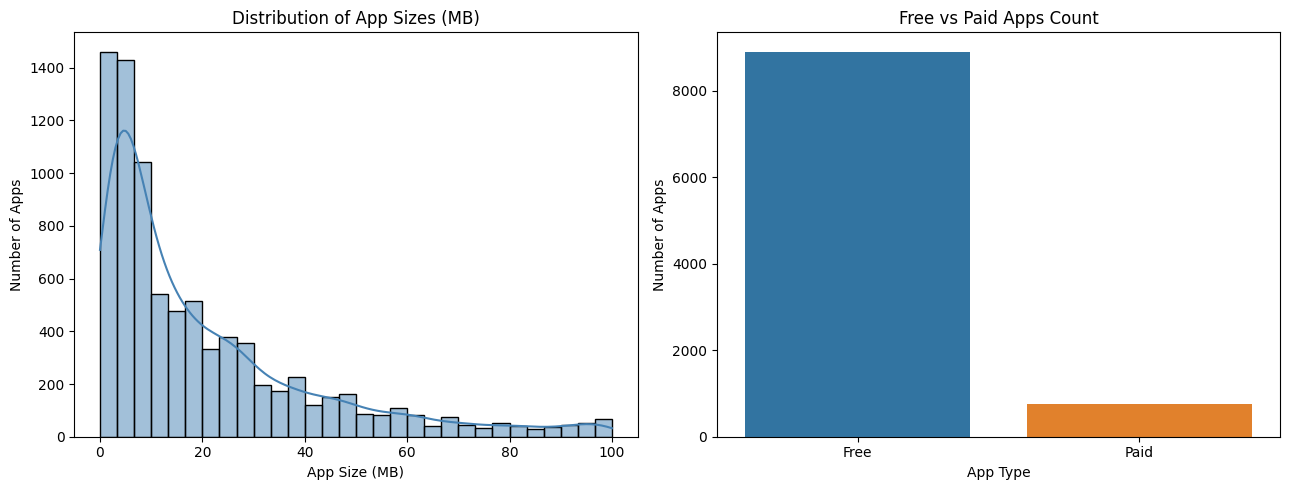

In [ ]:
# Count of Free vs Paid apps
type_counts = df['Type'].value_counts()
type_pct = (df['Type'].value_counts(normalize=True) * 100).round(2)
print("\n4. Free vs Paid Apps:")
display(pd.DataFrame({'Count': type_counts, 'Percentage (%)': type_pct}))

# Most common content rating
most_common_content = df['Content Rating'].mode()[0]
print(f"\n5. Most Common Content Rating: {most_common_content}")
display(df['Content Rating'].value_counts())

# Visualizations for Q3 (App Size Distribution) and Q4 (Free vs Paid Split)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Q3: Histogram of App Sizes
sns.histplot(df['Size_MB'].dropna(), bins=30, kde=True, ax=axes[0], color='steelblue')
axes[0].set_title('Distribution of App Sizes (MB)')
axes[0].set_xlabel('App Size (MB)')
axes[0].set_ylabel('Number of Apps')

# Q4: Bar chart of Free vs Paid Apps
sns.countplot(data=df, x='Type', hue='Type', legend=False, ax=axes[1])
axes[1].set_title('Free vs Paid Apps Count')
axes[1].set_xlabel('App Type')
axes[1].set_ylabel('Number of Apps')

plt.tight_layout()
plt.show()